# 02 · Preprocesamiento e ingeniería de características

Pasos: (1) limpiar y definir los targets, (2) crear features, (3) **split sin fuga**, (4) escalar y codificar, (5) seleccionar las 20 mejores columnas, (6) guardar los datos procesados en `data/processed/`.

La lógica vive en `src/data.py` y `src/features.py`.

In [1]:
import os
import sys

from pathlib import Path as _P

try:
    _aqui = _P(__vsc_ipynb_file__).resolve().parent
except NameError:
    _aqui = _P.cwd().resolve()
_raiz = next(p for p in [_aqui, *_aqui.parents] if (p / "src").is_dir())
os.chdir(_raiz)
sys.path.insert(0, str(_raiz))

import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from src.data import PROCESSED_DIR, clean_data, load_data, split_train_test
from src.features import (
    CATEGORICAL_COLS,
    NUMERIC_COLS,
    add_features,
    importance_table,
    make_preprocessor,
    make_selector,
)

SEED = 42
%matplotlib inline

## 1. Limpieza y targets (HU-04)

- **Clasificación:** `<30` → 1; `NO` y `>30` → 0.
- **Regresión (ADR-02):** `readmitted` es categórico, así que se codifica como escala ordinal `NO`=0, `>30`=1, `<30`=2.
- Se **excluyen** pacientes fallecidos o en hospicio (`discharge_disposition_id` ∈ {11, 13, 14, 19, 20, 21}): no pueden reingresar.

In [2]:
raw = load_data()
df = clean_data(raw)
pd.DataFrame(
    {"paso": ["Encuentros originales", "Sin fallecidos / hospicio"], "filas": [len(raw), len(df)]}
).assign(quitadas=lambda t: -t["filas"].diff().fillna(0).astype(int))

,paso,filas,quitadas
0,Encuentros originales,101766,0
1,Sin fallecidos / hospicio,99343,2423


In [3]:
y, y_reg, groups = df["target"], df["target_reg"], df["patient_nbr"]
print(
    f"{len(df):,} encuentros de {groups.nunique():,} pacientes · {y.mean():.1%} reingresa en <30 días"
)
pd.crosstab(df["readmitted"], df["target_reg"])

99,343 encuentros de 69,990 pacientes · 11.4% reingresa en <30 días


target_reg,0,1,2
readmitted,,,
<30,0,0,11314
>30,0,35502,0
NO,52527,0,0


## 2. Ingeniería de características (HU-05)

`add_features()` hace:

- **Se descartan** identificadores, `weight`, `payer_code`, `examide` y `citoglipton` (sin variación).
- **Edad a número:** `"[70-80)"` → 75.
- **`diag_1` agrupado** en 9 categorías (Diabetes, Circulatorio, Respiratorio, …).
- **Nulos:** glucosa y A1C → "No medido"; el resto de categóricas → "Desconocido".
- **3 features nuevas:** `visitas_previas`, `n_meds_activos`, `n_meds_cambiados`.

In [4]:
X = add_features(df)
print(
    f"X: {X.shape[0]:,} filas · {X.shape[1]} columnas ({len(NUMERIC_COLS)} numéricas + {len(CATEGORICAL_COLS)} categóricas)"
)
X.head()

X: 99,343 filas · 25 columnas (12 numéricas + 13 categóricas)


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,age_num,visitas_previas,...,discharge_disposition_id,admission_source_id,medical_specialty,diag_group,max_glu_serum,A1Cresult,insulin,metformin,change,diabetesMed
0,1,41,0,1,0,0,0,1,5.0,0,...,25,1,Pediatrics-Endocrinology,Diabetes,No medido,No medido,No,No,No,No
1,3,59,0,18,0,0,0,9,15.0,0,...,1,7,Desconocido,Otros,No medido,No medido,Up,No,Ch,Yes
2,2,11,5,13,2,0,1,6,25.0,3,...,1,7,Desconocido,Otros,No medido,No medido,No,No,No,Yes
3,2,44,1,16,0,0,0,7,35.0,0,...,1,7,Desconocido,Otros,No medido,No medido,Up,No,Ch,Yes
4,1,51,0,8,0,0,0,5,45.0,0,...,1,7,Desconocido,Neoplasias,No medido,No medido,Steady,No,Ch,Yes


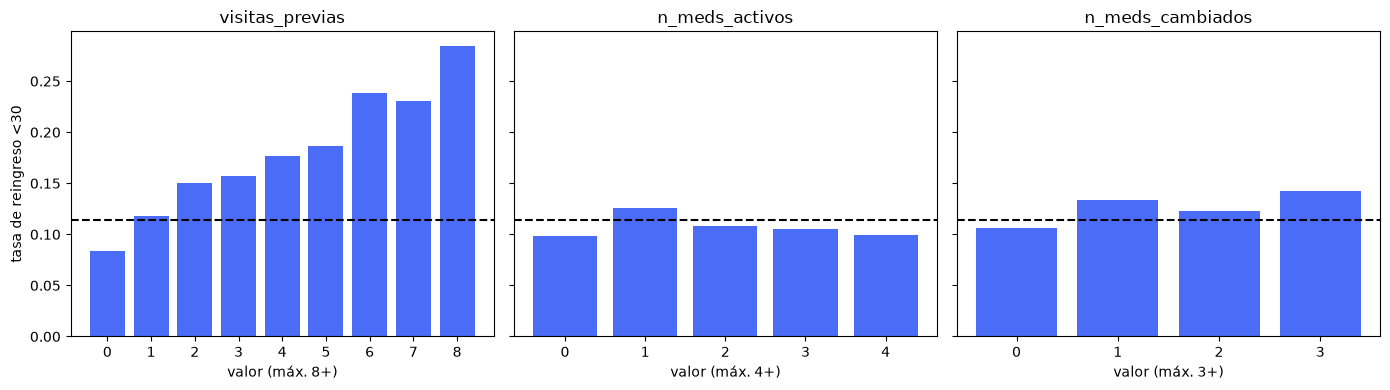

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, col, clip in zip(
    axes, ["visitas_previas", "n_meds_activos", "n_meds_cambiados"], [8, 4, 3], strict=True
):
    v = X[col].clip(upper=clip)
    ax.bar(y.groupby(v).mean().index.astype(str), y.groupby(v).mean().values, color="#4a6cf7")
    ax.axhline(y.mean(), color="k", ls="--")
    ax.set(title=col, xlabel=f"valor (máx. {clip}+)")
axes[0].set_ylabel("tasa de reingreso <30")
plt.tight_layout()
plt.show()

## 3. Split train/test sin fuga (HU-06)

Un mismo paciente tiene varios encuentros. Si se separan al azar, el paciente puede quedar en train **y** en test. Usamos `StratifiedGroupKFold` (vía `split_train_test`): **estratificado por target** y **agrupado por `patient_nbr`**.

In [6]:
tr, te = split_train_test(y, groups, seed=SEED)
X_train, X_test, y_train, y_test = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
yr_train, yr_test = y_reg.iloc[tr], y_reg.iloc[te]

assert set(groups.iloc[tr]).isdisjoint(groups.iloc[te])
print("Pacientes compartidos entre train y test:", len(set(groups.iloc[tr]) & set(groups.iloc[te])))
pd.DataFrame(
    {
        "filas": [len(tr), len(te)],
        "pacientes": [groups.iloc[tr].nunique(), groups.iloc[te].nunique()],
        "% reingreso <30": [y_train.mean() * 100, y_test.mean() * 100],
    },
    index=["train", "test"],
).round(2)

Pacientes compartidos entre train y test: 0


,filas,pacientes,% reingreso <30
train,79473,55952,11.39
test,19870,14038,11.39


## 4. Escalado y codificación
- Las numéricas tienen rangos muy distintos (`time_in_hospital` 1–14, `num_lab_procedures` 1–130, `number_inpatient` 0–20). Sin escalar, las de mayor magnitud dominan la distancia del kernel RBF de la SVM y de la red neuronal, y la optimización converge peor.
- Los modelos basados en árboles (Decision Tree, Random Forest) son invariantes a transformaciones monótonas: escalar no los afecta, solo no les aporta nada.



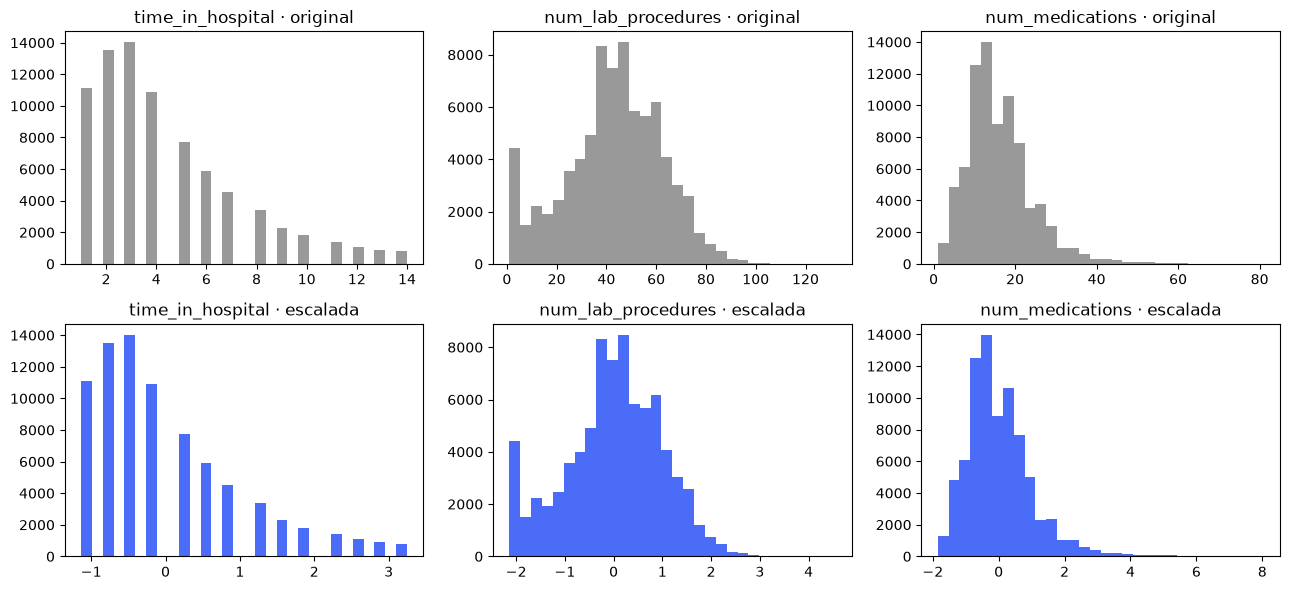

In [7]:
demo = ["time_in_hospital", "num_lab_procedures", "num_medications"]
sc = StandardScaler().fit(X_train[demo])
train_esc = pd.DataFrame(sc.transform(X_train[demo]), columns=demo)
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for j, col in enumerate(demo):
    axes[0, j].hist(X_train[col], bins=30, color="#999")
    axes[0, j].set(title=f"{col} · original")
    axes[1, j].hist(train_esc[col], bins=30, color="#4a6cf7")
    axes[1, j].set(title=f"{col} · escalada")
plt.tight_layout()
plt.show()

In [8]:
pre = make_preprocessor().fit(X_train)
Xt = pre.transform(X_train)
print(f"Antes: {X_train.shape[1]} columnas  ->  Después: {Xt.shape[1]} columnas")
print(
    "Media de las numéricas en train (≈0):",
    np.round(Xt[:, : len(NUMERIC_COLS)].mean(axis=0)[:3], 3),
)
print(
    "Media de las numéricas en test  (cerca de 0, pero no exacta):",
    np.round(pre.transform(X_test)[:, : len(NUMERIC_COLS)].mean(axis=0)[:3], 3),
)

Antes: 25 columnas  ->  Después: 91 columnas
Media de las numéricas en train (≈0): [-0. -0.  0.]
Media de las numéricas en test  (cerca de 0, pero no exacta): [0.015 0.003 0.007]


In [9]:
# Comprobación del escalado: en train media ≈ 0 y desviación ≈ 1 (por construcción);
# en test solo aproximadamente, porque se usan μ y σ de train.
Xs_train = pd.DataFrame(Xt[:, : len(NUMERIC_COLS)], columns=NUMERIC_COLS)
Xs_test = pd.DataFrame(pre.transform(X_test)[:, : len(NUMERIC_COLS)], columns=NUMERIC_COLS)
pd.DataFrame(
    {
        "rango_original": [f"{X_train[c].min():g} – {X_train[c].max():g}" for c in NUMERIC_COLS],
        "media_train": Xs_train.mean().round(3).values,
        "std_train": Xs_train.std(ddof=0).round(3).values,
        "media_test": Xs_test.mean().round(3).values,
    },
    index=NUMERIC_COLS,
)

,rango_original,media_train,std_train,media_test
time_in_hospital,1 – 14,-0.0,1.0,0.015
num_lab_procedures,1 – 132,0.0,1.0,0.003
num_procedures,0 – 6,-0.0,1.0,0.007
num_medications,1 – 81,0.0,1.0,0.007
number_outpatient,0 – 42,-0.0,1.0,-0.009
number_emergency,0 – 76,0.0,1.0,0.009
number_inpatient,0 – 21,0.0,1.0,0.002
number_diagnoses,1 – 16,0.0,1.0,0.001
age_num,5 – 95,-0.0,1.0,0.006
visitas_previas,0 – 80,-0.0,1.0,-0.000


## 5. Selección de las 20 mejores columnas

Importancia de un Random Forest sobre las columnas ya transformadas; nos quedamos con las 20 mejores y lo justificamos con la importancia acumulada.

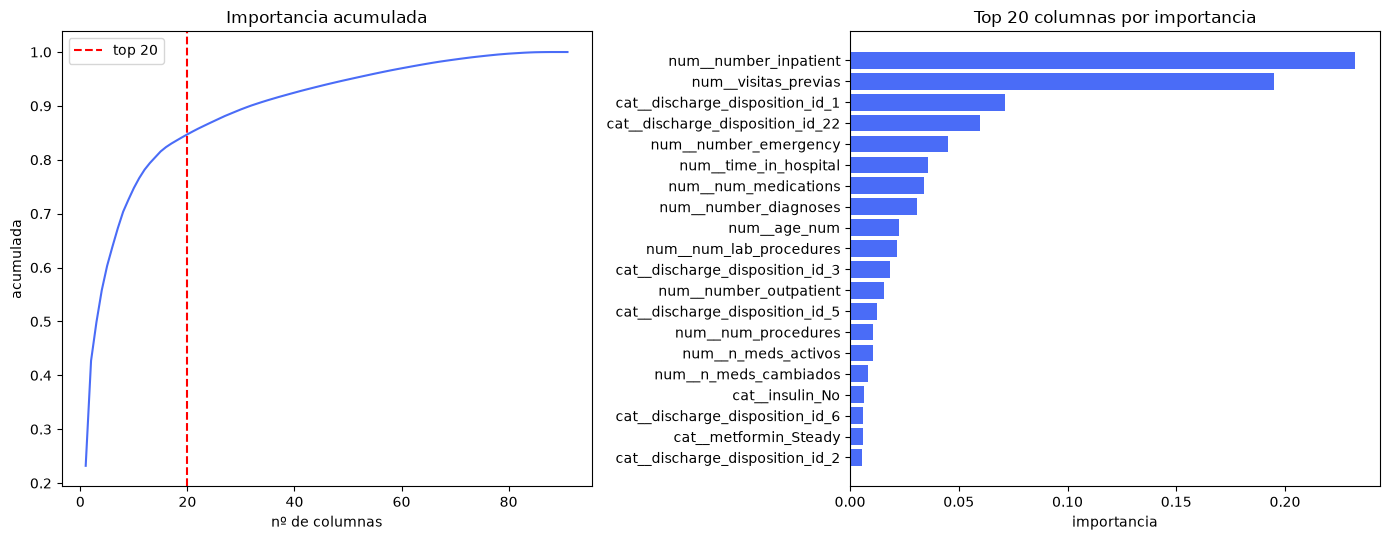

Las 20 primeras concentran el 85% de la importancia (de 91 columnas).


In [10]:
tabla = importance_table(X_train, y_train)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].plot(range(1, len(tabla) + 1), tabla["acumulada"], color="#4a6cf7")
axes[0].axvline(20, color="red", ls="--", label="top 20")
axes[0].set(title="Importancia acumulada", xlabel="nº de columnas", ylabel="acumulada")
axes[0].legend()
top = tabla.head(20).iloc[::-1]
axes[1].barh(top["feature"], top["importance"], color="#4a6cf7")
axes[1].set(title="Top 20 columnas por importancia", xlabel="importancia")
plt.tight_layout()
plt.show()
print(
    f"Las 20 primeras concentran el {tabla.loc[19, 'acumulada']:.0%} de la importancia (de {len(tabla)} columnas)."
)

In [11]:
# Dentro del Pipeline la selección la hace SelectFromModel. Comprobamos que elige lo mismo:
sel = Pipeline([("prep", make_preprocessor()), ("select", make_selector(20))]).fit(X_train, y_train)
print("¿Coincide con la tabla?", set(sel.get_feature_names_out()) == set(tabla.head(20)["feature"]))

¿Coincide con la tabla? True


## 6. Guardar datos procesados

Se guardan en `data/processed/` (no se versionan). En el modelado el preprocesador vive dentro del `Pipeline`, así que se ajusta solo con los datos de entrenamiento de cada fold.

In [12]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
X_train.assign(target=y_train, target_reg=yr_train, patient_nbr=groups.iloc[tr]).to_csv(
    PROCESSED_DIR / "train.csv", index=False
)
X_test.assign(target=y_test, target_reg=yr_test, patient_nbr=groups.iloc[te]).to_csv(
    PROCESSED_DIR / "test.csv", index=False
)
print("Guardado:", sorted(p.name for p in PROCESSED_DIR.iterdir()))

Guardado: ['test.csv', 'train.csv']
